<a href="https://colab.research.google.com/github/SAMBOAH95/Machine-Learning-Projects/blob/main/Level2/Task5_Movie_Recommendation_System/Movie_Recommendation_System_Task5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:

from google.colab import drive

drive.mount('/content/drive')


Mounted at /content/drive


In [3]:

import os

project_path = "/content/drive/MyDrive/Elevo/Level2/Task5"

print("Project folder exists:", os.path.exists(project_path))
print("Project path:", project_path)


Project folder exists: True
Project path: /content/drive/MyDrive/Elevo/Level2/Task5


In [4]:

import requests
import zipfile
import io

url = "https://files.grouplens.org/datasets/movielens/ml-100k.zip"

response = requests.get(url)
response.raise_for_status()

# Save and extract the dataset
with zipfile.ZipFile(io.BytesIO(response.content)) as zip_ref:
    zip_ref.extractall(project_path)

print("MovieLens 100K downloaded and extracted successfully!")


MovieLens 100K downloaded and extracted successfully!


In [5]:

dataset_path = os.path.join(project_path, "ml-100k")

print(os.listdir(dataset_path))


['allbut.pl', 'mku.sh', 'README', 'u.data', 'u.genre', 'u.info', 'u.item', 'u.occupation', 'u.user', 'u1.base', 'u1.test', 'u2.base', 'u2.test', 'u3.base', 'u3.test', 'u4.base', 'u4.test', 'u5.base', 'u5.test', 'ua.base', 'ua.test', 'ub.base', 'ub.test']


In [6]:

import pandas as pd
import numpy as np

ratings = pd.read_csv(
    os.path.join(dataset_path, "u.data"),
    sep="\t",
    names=["user_id", "movie_id", "rating", "timestamp"]
)

ratings.head()


,user_id,movie_id,rating,timestamp
0,196,242,3,881250949
1,186,302,3,891717742
2,22,377,1,878887116
3,244,51,2,880606923
4,166,346,1,886397596


In [7]:

print("Dataset Information:")
ratings.info()

print("\nDataset Shape:", ratings.shape)

print("\nMissing Values:")
print(ratings.isnull().sum())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype
---  ------     --------------   -----
 0   user_id    100000 non-null  int64
 1   movie_id   100000 non-null  int64
 2   rating     100000 non-null  int64
 3   timestamp  100000 non-null  int64
dtypes: int64(4)
memory usage: 3.1 MB

Dataset Shape: (100000, 4)

Missing Values:
user_id      0
movie_id     0
rating       0
timestamp    0
dtype: int64


In [8]:

movies = pd.read_csv(
    os.path.join(dataset_path, "u.item"),
    sep="|",
    encoding="latin-1",
    header=None,
    usecols=[0, 1],
    names=["movie_id", "title"]
)

movies.head()

,movie_id,title
0,1,Toy Story (1995)
1,2,GoldenEye (1995)
2,3,Four Rooms (1995)
3,4,Get Shorty (1995)
4,5,Copycat (1995)


In [9]:

print("Movies Dataset Shape:", movies.shape)

print("\nDataset Information:")
movies.info()

print("\nMissing Values:")
print(movies.isnull().sum())


Movies Dataset Shape: (1682, 2)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1682 entries, 0 to 1681
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   movie_id  1682 non-null   int64 
 1   title     1682 non-null   object
dtypes: int64(1), object(1)
memory usage: 26.4+ KB

Missing Values:
movie_id    0
title       0
dtype: int64


In [10]:

print("Total ratings:", len(ratings))
print("Unique users:", ratings["user_id"].nunique())
print("Unique movies rated:", ratings["movie_id"].nunique())

print("\nRating Distribution:")
print(ratings["rating"].value_counts().sort_index())


Total ratings: 100000
Unique users: 943
Unique movies rated: 1682

Rating Distribution:
rating
1     6110
2    11370
3    27145
4    34174
5    21201
Name: count, dtype: int64


In [11]:

average_rating = ratings["rating"].mean()
median_rating = ratings["rating"].median()

print("Average Movie Rating:", round(average_rating, 2))
print("Median Movie Rating:", median_rating)


Average Movie Rating: 3.53
Median Movie Rating: 4.0


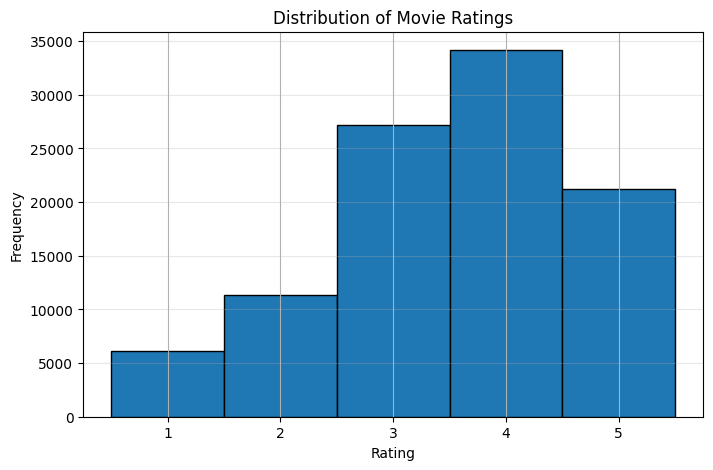

In [12]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

ratings["rating"].hist(
    bins=np.arange(0.5, 6.5, 1),
    edgecolor="black"
)

plt.title("Distribution of Movie Ratings")
plt.xlabel("Rating")
plt.ylabel("Frequency")
plt.xticks([1, 2, 3, 4, 5])
plt.grid(axis="y", alpha=0.3)

plt.show()


In [13]:

plt.savefig(
    os.path.join(project_path, "rating_distribution.png"),
    dpi=300,
    bbox_inches="tight"
)

print("Rating distribution graph saved successfully!")


Rating distribution graph saved successfully!


<Figure size 640x480 with 0 Axes>

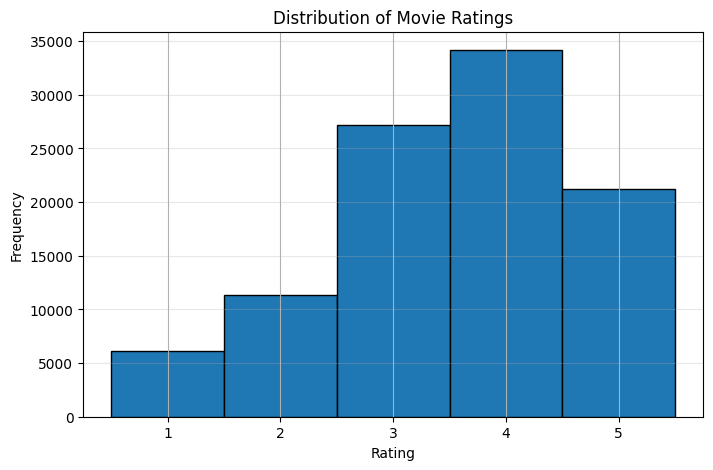

Histogram saved successfully!


In [14]:

plt.figure(figsize=(8, 5))

ratings["rating"].hist(
    bins=np.arange(0.5, 6.5, 1),
    edgecolor="black"
)

plt.title("Distribution of Movie Ratings")
plt.xlabel("Rating")
plt.ylabel("Frequency")
plt.xticks([1, 2, 3, 4, 5])
plt.grid(axis="y", alpha=0.3)

# Save before displaying
plt.savefig(
    os.path.join(project_path, "rating_distribution.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Histogram saved successfully!")


In [15]:

user_activity = ratings.groupby("user_id")["movie_id"].count()

print("Average movies rated per user:", round(user_activity.mean(), 2))
print("Maximum movies rated by one user:", user_activity.max())
print("Minimum movies rated by one user:", user_activity.min())


Average movies rated per user: 106.04
Maximum movies rated by one user: 737
Minimum movies rated by one user: 20


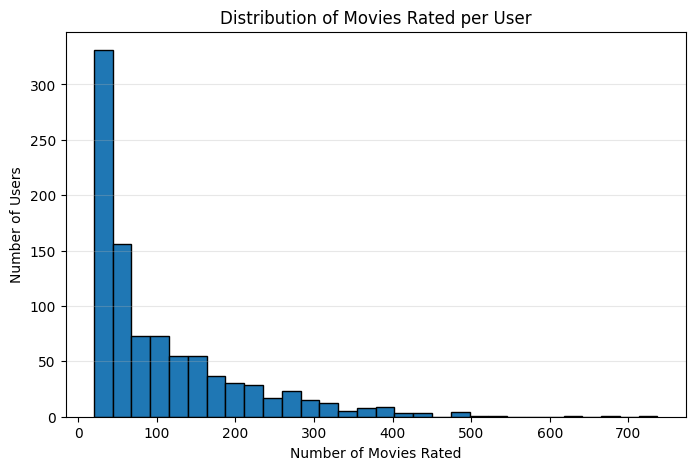

In [16]:

plt.figure(figsize=(8, 5))

plt.hist(user_activity, bins=30, edgecolor="black")

plt.title("Distribution of Movies Rated per User")
plt.xlabel("Number of Movies Rated")
plt.ylabel("Number of Users")
plt.grid(axis="y", alpha=0.3)

plt.savefig(
    os.path.join(project_path, "user_activity_distribution.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [17]:

movie_popularity = ratings.groupby("movie_id")["rating"].count()

print("Average ratings per movie:", round(movie_popularity.mean(), 2))
print("Maximum ratings for a movie:", movie_popularity.max())
print("Minimum ratings for a movie:", movie_popularity.min())


Average ratings per movie: 59.45
Maximum ratings for a movie: 583
Minimum ratings for a movie: 1


In [18]:

top_movies = movie_popularity.sort_values(ascending=False).head(10)

top_movies_df = top_movies.reset_index()
top_movies_df.columns = ["movie_id", "number_of_ratings"]

top_movies_df = top_movies_df.merge(
    movies,
    on="movie_id",
    how="left"
)

top_movies_df = top_movies_df[
    ["movie_id", "title", "number_of_ratings"]
]

display(top_movies_df)


,movie_id,title,number_of_ratings
0,50,Star Wars (1977),583
1,258,Contact (1997),509
2,100,Fargo (1996),508
3,181,Return of the Jedi (1983),507
4,294,Liar Liar (1997),485
5,286,"English Patient, The (1996)",481
6,288,Scream (1996),478
7,1,Toy Story (1995),452
8,300,Air Force One (1997),431
9,121,Independence Day (ID4) (1996),429


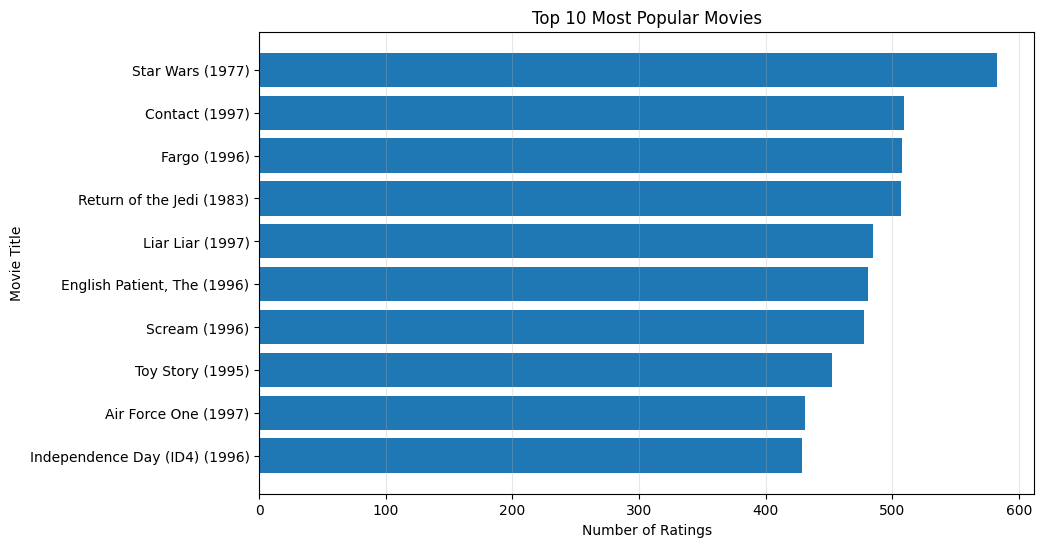

In [19]:

plt.figure(figsize=(10, 6))

plt.barh(
    top_movies_df["title"],
    top_movies_df["number_of_ratings"]
)

plt.title("Top 10 Most Popular Movies")
plt.xlabel("Number of Ratings")
plt.ylabel("Movie Title")
plt.gca().invert_yaxis()
plt.grid(axis="x", alpha=0.3)

plt.savefig(
    os.path.join(project_path, "top_10_popular_movies.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [20]:

user_item_matrix = ratings.pivot_table(
    index="user_id",
    columns="movie_id",
    values="rating"
)

print("User-Item Matrix Shape:", user_item_matrix.shape)

display(user_item_matrix.head())


User-Item Matrix Shape: (943, 1682)


movie_id,1,2,3,4,5,6,7,8,9,10,...,1673,1674,1675,1676,1677,1678,1679,1680,1681,1682
user_id,,,,,,,,,,,,,,,,,,,,,
1,5.0,3.0,4.0,3.0,3.0,5.0,4.0,1.0,5.0,3.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,4.0,3.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [21]:

total_cells = user_item_matrix.size

missing_cells = user_item_matrix.isna().sum().sum()

sparsity = (missing_cells / total_cells) * 100

print("Total matrix cells:", total_cells)
print("Missing cells:", missing_cells)
print("Matrix sparsity:", round(sparsity, 2), "%")


Total matrix cells: 1586126
Missing cells: 1486126
Matrix sparsity: 93.7 %


In [22]:

user_item_matrix.to_csv(
    os.path.join(project_path, "user_item_matrix.csv")
)

print("User-item matrix saved successfully!")


User-item matrix saved successfully!


In [23]:

from sklearn.metrics.pairwise import cosine_similarity

print("Cosine similarity imported successfully!")


Cosine similarity imported successfully!


In [24]:

user_item_filled = user_item_matrix.fillna(0)

print("Missing values after filling:", user_item_filled.isna().sum().sum())

display(user_item_filled.head())


Missing values after filling: 0


movie_id,1,2,3,4,5,6,7,8,9,10,...,1673,1674,1675,1676,1677,1678,1679,1680,1681,1682
user_id,,,,,,,,,,,,,,,,,,,,,
1,5.0,3.0,4.0,3.0,3.0,5.0,4.0,1.0,5.0,3.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,4.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,4.0,3.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [25]:

user_similarity = cosine_similarity(user_item_filled)

# Convert similarity array into a DataFrame
user_similarity_df = pd.DataFrame(
    user_similarity,
    index=user_item_filled.index,
    columns=user_item_filled.index
)

print("User Similarity Matrix Shape:", user_similarity_df.shape)

display(user_similarity_df.iloc[:5, :5])


User Similarity Matrix Shape: (943, 943)


user_id,1,2,3,4,5
user_id,,,,,
1,1.000000,0.166931,0.047460,0.064358,0.378475
2,0.166931,1.000000,0.110591,0.178121,0.072979
3,0.047460,0.110591,1.000000,0.344151,0.021245
4,0.064358,0.178121,0.344151,1.000000,0.031804
5,0.378475,0.072979,0.021245,0.031804,1.000000


In [26]:

target_user = 1

similar_users = user_similarity_df[target_user].sort_values(
    ascending=False
)

# Exclude the target user
similar_users = similar_users.drop(target_user)

# Get top 5 similar users
top_5_similar_users = similar_users.head(5)

print("Top 5 Similar Users to User", target_user)
display(top_5_similar_users)


Top 5 Similar Users to User 1


,1
user_id,
916,0.569066
864,0.547548
268,0.542077
92,0.540534
435,0.538665


In [27]:

# Movies already rated by User 1
user_rated_movies = ratings[
    ratings["user_id"] == target_user
]["movie_id"].tolist()

print("User 1 has rated", len(user_rated_movies), "movies")

print("\nFirst 10 movies rated by User 1:")
print(user_rated_movies[:10])


User 1 has rated 272 movies

First 10 movies rated by User 1:
[61, 189, 33, 160, 20, 202, 171, 265, 155, 117]


In [28]:

# Get ratings from the five most similar users
similar_user_ids = top_5_similar_users.index

similar_users_ratings = ratings[
    ratings["user_id"].isin(similar_user_ids)
]

# Select highly rated movies (4 or 5 stars)
highly_rated_movies = similar_users_ratings[
    similar_users_ratings["rating"] >= 4
]

# Exclude movies already rated by User 1
unseen_movies = highly_rated_movies[
    ~highly_rated_movies["movie_id"].isin(user_rated_movies)
]

# Count recommendations from similar users
movie_recommendations = (
    unseen_movies.groupby("movie_id")
    .agg(
        recommendation_count=("rating", "count"),
        average_rating=("rating", "mean")
    )
    .sort_values(
        by=["recommendation_count", "average_rating"],
        ascending=False
    )
)

print("Number of unseen movies identified:", len(movie_recommendations))

display(movie_recommendations.head(10))


Number of unseen movies identified: 211


,recommendation_count,average_rating
movie_id,,
403,4,4.250000
474,4,4.250000
483,3,5.000000
273,3,4.666667
276,3,4.666667
286,3,4.666667
318,3,4.666667
408,3,4.666667
433,3,4.666667


In [29]:

recommended_movies = movie_recommendations.reset_index()

recommended_movies = recommended_movies.merge(
    movies,
    on="movie_id",
    how="left"
)

recommended_movies = recommended_movies[
    ["movie_id", "title", "recommendation_count", "average_rating"]
]

print("Top 10 Movie Recommendations for User 1")

display(recommended_movies.head(10))


Top 10 Movie Recommendations for User 1


,movie_id,title,recommendation_count,average_rating
0,403,Batman (1989),4,4.250000
1,474,Dr. Strangelove or: How I Learned to Stop Worr...,4,4.250000
2,483,Casablanca (1942),3,5.000000
3,273,Heat (1995),3,4.666667
4,276,Leaving Las Vegas (1995),3,4.666667
5,286,"English Patient, The (1996)",3,4.666667
6,318,Schindler's List (1993),3,4.666667
7,408,"Close Shave, A (1995)",3,4.666667
8,433,Heathers (1989),3,4.666667
9,582,"Piano, The (1993)",3,4.666667


In [30]:

recommendation_path = os.path.join(
    project_path,
    "user_based_recommendations.csv"
)

recommended_movies.head(10).to_csv(
    recommendation_path,
    index=False
)

print("Recommendations saved successfully!")
print("Saved to:", recommendation_path)


Recommendations saved successfully!
Saved to: /content/drive/MyDrive/Elevo/Level2/Task5/user_based_recommendations.csv


In [31]:

# Get similarity scores of the five nearest users
similarity_weights = top_5_similar_users

print("Similarity weights for User 1:")
display(similarity_weights)


Similarity weights for User 1:


,1
user_id,
916,0.569066
864,0.547548
268,0.542077
92,0.540534
435,0.538665


In [32]:

# Calculate weighted scores for unseen movies
weighted_recommendations = {}

for movie_id in movie_recommendations.index:

    movie_ratings = similar_users_ratings[
        similar_users_ratings["movie_id"] == movie_id
    ]

    weighted_sum = 0
    similarity_sum = 0

    for _, row in movie_ratings.iterrows():
        user_id = row["user_id"]

        similarity = similarity_weights[user_id]

        weighted_sum += similarity * row["rating"]
        similarity_sum += similarity

    if similarity_sum > 0:
        weighted_recommendations[movie_id] = (
            weighted_sum / similarity_sum
        )

print("Weighted predictions calculated:", len(weighted_recommendations))


Weighted predictions calculated: 211


In [33]:

weighted_recommendations_df = pd.DataFrame(
    weighted_recommendations.items(),
    columns=["movie_id", "predicted_rating"]
)

weighted_recommendations_df = weighted_recommendations_df.merge(
    movies,
    on="movie_id",
    how="left"
)

weighted_recommendations_df = weighted_recommendations_df.sort_values(
    by="predicted_rating",
    ascending=False
)

print("Top 10 Similarity-Weighted Recommendations for User 1:")

display(weighted_recommendations_df.head(10))


Top 10 Similarity-Weighted Recommendations for User 1:


,movie_id,predicted_rating,title
27,919,5.0,"City of Lost Children, The (1995)"
25,313,5.0,Titanic (1997)
2,483,5.0,Casablanca (1942)
75,283,5.0,Emma (1996)
76,302,5.0,L.A. Confidential (1997)
78,331,5.0,"Edge, The (1997)"
82,430,5.0,Duck Soup (1933)
26,343,5.0,Alien: Resurrection (1997)
85,518,5.0,Miller's Crossing (1990)
84,512,5.0,Wings of Desire (1987)


In [34]:

weighted_path = os.path.join(
    project_path,
    "weighted_user_recommendations.csv"
)

weighted_recommendations_df.head(10).to_csv(
    weighted_path,
    index=False
)

print("Weighted recommendations saved successfully!")
print("Saved to:", weighted_path)

Weighted recommendations saved successfully!
Saved to: /content/drive/MyDrive/Elevo/Level2/Task5/weighted_user_recommendations.csv


In [35]:
# Load the official MovieLens training dataset
train_ratings = pd.read_csv(
    os.path.join(dataset_path, "u1.base"),
    sep="\t",
    names=["user_id", "movie_id", "rating", "timestamp"]
)

# Load the official MovieLens testing dataset
test_ratings = pd.read_csv(
    os.path.join(dataset_path, "u1.test"),
    sep="\t",
    names=["user_id", "movie_id", "rating", "timestamp"]
)

print("Training dataset shape:", train_ratings.shape)
print("Testing dataset shape:", test_ratings.shape)

print("\nTraining data preview:")
display(train_ratings.head())

print("\nTesting data preview:")
display(test_ratings.head())

Training dataset shape: (80000, 4)
Testing dataset shape: (20000, 4)

Training data preview:


,user_id,movie_id,rating,timestamp
0,1,1,5,874965758
1,1,2,3,876893171
2,1,3,4,878542960
3,1,4,3,876893119
4,1,5,3,889751712



Testing data preview:


,user_id,movie_id,rating,timestamp
0,1,6,5,887431973
1,1,10,3,875693118
2,1,12,5,878542960
3,1,14,5,874965706
4,1,17,3,875073198


In [36]:
# Create user-item matrix using training data only
train_user_item_matrix = train_ratings.pivot_table(
    index="user_id",
    columns="movie_id",
    values="rating"
)

# Replace missing values with zero
train_user_item_filled = train_user_item_matrix.fillna(0)

print("Training user-item matrix shape:",
      train_user_item_matrix.shape)

print("Filled matrix shape:",
      train_user_item_filled.shape)

print("\nFirst five rows:")
display(train_user_item_filled.head())

Training user-item matrix shape: (943, 1650)
Filled matrix shape: (943, 1650)

First five rows:


movie_id,1,2,3,4,5,6,7,8,9,10,...,1673,1674,1675,1676,1677,1678,1679,1680,1681,1682
user_id,,,,,,,,,,,,,,,,,,,,,
1,5.0,3.0,4.0,3.0,3.0,0.0,4.0,1.0,5.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,4.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [37]:
# Calculate cosine similarity between users
train_user_similarity = cosine_similarity(
    train_user_item_filled
)

# Convert similarity array into a DataFrame
train_user_similarity_df = pd.DataFrame(
    train_user_similarity,
    index=train_user_item_filled.index,
    columns=train_user_item_filled.index
)

print("User similarity matrix shape:",
      train_user_similarity_df.shape)

print("\nSimilarity scores for the first five users:")
display(train_user_similarity_df.iloc[:5, :5])

User similarity matrix shape: (943, 943)

Similarity scores for the first five users:


user_id,1,2,3,4,5
user_id,,,,,
1,1.000000,0.097021,0.052469,0.021162,0.193545
2,0.097021,1.000000,0.051348,0.084426,0.015516
3,0.052469,0.051348,1.000000,0.145660,0.037180
4,0.021162,0.084426,0.145660,1.000000,0.017291
5,0.193545,0.015516,0.037180,0.017291,1.000000


In [38]:
# Select the target user
target_user = 1

# Get similarity scores for the target user
similar_users = train_user_similarity_df[target_user]

# Remove the target user from the results
similar_users = similar_users.drop(target_user)

# Select the 20 most similar users
top_20_similar_users = similar_users.sort_values(
    ascending=False
).head(20)

print("Top 20 users most similar to User 1:")
display(top_20_similar_users)

Top 20 users most similar to User 1:


,1
user_id,
823,0.405729
514,0.394819
864,0.381792
592,0.371713
521,0.367758
727,0.367747
889,0.366763
606,0.364904
622,0.364041


In [39]:
# Get movies already rated by User 1 in training data
user_rated_movies = train_ratings[
    train_ratings["user_id"] == target_user
]["movie_id"].tolist()

# Get the IDs of the 20 similar users
similar_user_ids = top_20_similar_users.index

# Get ratings from the 20 similar users
similar_users_ratings = train_ratings[
    train_ratings["user_id"].isin(similar_user_ids)
]

# Select highly rated movies (rating >= 4)
highly_rated_movies = similar_users_ratings[
    similar_users_ratings["rating"] >= 4
]

# Remove movies already rated by User 1
unseen_movies = highly_rated_movies[
    ~highly_rated_movies["movie_id"].isin(user_rated_movies)
]

# Rank candidate movies
movie_recommendations = (
    unseen_movies.groupby("movie_id")
    .agg(
        recommendation_count=("rating", "count"),
        average_rating=("rating", "mean")
    )
    .sort_values(
        by=["recommendation_count", "average_rating"],
        ascending=False
    )
)

print("Number of unseen candidate movies:",
      len(movie_recommendations))

print("\nTop 10 recommended movies:")
display(movie_recommendations.head(10))

Number of unseen candidate movies: 537

Top 10 recommended movies:


,recommendation_count,average_rating
movie_id,,
174,19,4.578947
96,18,4.611111
98,18,4.555556
12,17,4.705882
56,17,4.647059
64,15,4.800000
69,15,4.466667
100,14,4.785714
655,14,4.357143


In [40]:
# Convert recommendations into a DataFrame
recommended_movies = movie_recommendations.reset_index()

# Add movie titles
recommended_movies = recommended_movies.merge(
    movies,
    on="movie_id",
    how="left"
)

# Select and display the relevant columns
recommended_movies = recommended_movies[
    ["movie_id", "title", "recommendation_count", "average_rating"]
]

print("Top 10 movie recommendations for User 1:")
display(recommended_movies.head(10))

Top 10 movie recommendations for User 1:


,movie_id,title,recommendation_count,average_rating
0,174,Raiders of the Lost Ark (1981),19,4.578947
1,96,Terminator 2: Judgment Day (1991),18,4.611111
2,98,"Silence of the Lambs, The (1991)",18,4.555556
3,12,"Usual Suspects, The (1995)",17,4.705882
4,56,Pulp Fiction (1994),17,4.647059
5,64,"Shawshank Redemption, The (1994)",15,4.800000
6,69,Forrest Gump (1994),15,4.466667
7,100,Fargo (1996),14,4.785714
8,655,Stand by Me (1986),14,4.357143
9,186,"Blues Brothers, The (1980)",14,4.285714


In [41]:
# Set K to 10
K = 10

# Get User 1's relevant movies from the test dataset
relevant_movies = test_ratings[
    (test_ratings["user_id"] == target_user) &
    (test_ratings["rating"] >= 4)
]["movie_id"].tolist()

# Get the top 10 recommended movie IDs
top_k_recommendations = recommended_movies.head(K)[
    "movie_id"
].tolist()

# Identify relevant recommended movies
relevant_recommendations = set(
    top_k_recommendations
).intersection(set(relevant_movies))

# Calculate Precision@10
precision_at_k = len(relevant_recommendations) / K

print("User:", target_user)
print("K:", K)
print("Number of relevant recommendations:",
      len(relevant_recommendations))
print("Relevant recommended movie IDs:",
      relevant_recommendations)
print("Precision@10:", round(precision_at_k, 4))

User: 1
K: 10
Number of relevant recommendations: 8
Relevant recommended movie IDs: {96, 64, 98, 100, 12, 174, 56, 186}
Precision@10: 0.8


In [42]:
# Evaluation settings
K = 10
N_NEIGHBORS = 20

precision_scores = []

# Evaluate each user
for user_id in train_user_item_filled.index:

    # Find the user's 20 most similar neighbours
    similarities = train_user_similarity_df[user_id].drop(user_id)

    top_neighbors = similarities.sort_values(
        ascending=False
    ).head(N_NEIGHBORS)

    neighbor_ids = top_neighbors.index

    # Get movies already rated by the target user
    rated_movies = set(
        train_ratings[
            train_ratings["user_id"] == user_id
        ]["movie_id"]
    )

    # Get ratings from similar users
    neighbor_ratings = train_ratings[
        train_ratings["user_id"].isin(neighbor_ids)
    ]

    # Select highly rated movies
    high_ratings = neighbor_ratings[
        neighbor_ratings["rating"] >= 4
    ]

    # Remove movies already rated by the target user
    candidates = high_ratings[
        ~high_ratings["movie_id"].isin(rated_movies)
    ]

    # Rank candidate movies
    ranked_movies = (
        candidates.groupby("movie_id")
        .agg(
            recommendation_count=("rating", "count"),
            average_rating=("rating", "mean")
        )
        .sort_values(
            by=["recommendation_count", "average_rating"],
            ascending=False
        )
    )

    # Select the top K recommendations
    top_recommendations = set(
        ranked_movies.head(K).index
    )

    # Get relevant movies from the test dataset
    relevant_movies = set(
        test_ratings[
            (test_ratings["user_id"] == user_id) &
            (test_ratings["rating"] >= 4)
        ]["movie_id"]
    )

    # Skip users without relevant test movies or enough recommendations
    if len(relevant_movies) == 0 or len(top_recommendations) < K:
        continue

    # Calculate Precision@K
    relevant_recommendations = (
        top_recommendations.intersection(relevant_movies)
    )

    precision = len(relevant_recommendations) / K
    precision_scores.append(precision)

# Calculate overall performance
mean_precision = np.mean(precision_scores)

print("Number of users evaluated:", len(precision_scores))
print("Precision@10:", round(mean_precision, 4))
print("Precision@10 (%):", round(mean_precision * 100, 2), "%")

Number of users evaluated: 456
Precision@10: 0.3561
Precision@10 (%): 35.61 %


In [43]:
# Calculate descriptive statistics
precision_summary = pd.Series(
    precision_scores,
    name="Precision@10"
).describe()

print("Precision@10 Performance Summary:")
display(precision_summary)

print("\nMedian Precision@10:",
      round(np.median(precision_scores), 4))

print("Standard Deviation:",
      round(np.std(precision_scores), 4))

Precision@10 Performance Summary:


,Precision@10
count,456.000000
mean,0.356140
std,0.254208
min,0.000000
25%,0.200000
50%,0.300000
75%,0.500000
max,1.000000



Median Precision@10: 0.3
Standard Deviation: 0.2539


In [44]:
# Evaluation settings
K_values = [5, 10, 20]
N_NEIGHBORS = 20

precision_results = {k: [] for k in K_values}

# Evaluate all users
for user_id in train_user_item_filled.index:

    # Find the 20 most similar users
    similarities = train_user_similarity_df[user_id].drop(user_id)
    top_neighbors = similarities.sort_values(
        ascending=False
    ).head(N_NEIGHBORS)

    # Get movies already rated by target user
    rated_movies = set(
        train_ratings[
            train_ratings["user_id"] == user_id
        ]["movie_id"]
    )

    # Get ratings from similar users
    neighbor_ratings = train_ratings[
        train_ratings["user_id"].isin(top_neighbors.index)
    ]

    # Select highly rated movies not seen by target user
    candidates = neighbor_ratings[
        (neighbor_ratings["rating"] >= 4) &
        (~neighbor_ratings["movie_id"].isin(rated_movies))
    ]

    # Rank candidate movies
    ranked_movies = (
        candidates.groupby("movie_id")
        .agg(
            recommendation_count=("rating", "count"),
            average_rating=("rating", "mean")
        )
        .sort_values(
            by=["recommendation_count", "average_rating"],
            ascending=False
        )
    )

    # Get relevant movies from test data
    relevant_movies = set(
        test_ratings[
            (test_ratings["user_id"] == user_id) &
            (test_ratings["rating"] >= 4)
        ]["movie_id"]
    )

    # Require at least 20 candidates and one relevant test movie
    if len(ranked_movies) < 20 or len(relevant_movies) == 0:
        continue

    # Calculate Precision@5, @10 and @20
    for k in K_values:
        top_k = set(ranked_movies.head(k).index)

        relevant_recommendations = (
            top_k.intersection(relevant_movies)
        )

        precision = len(relevant_recommendations) / k
        precision_results[k].append(precision)

# Display results
precision_comparison = pd.DataFrame({
    "K": K_values,
    "Mean_Precision": [
        np.mean(precision_results[k]) for k in K_values
    ]
})

precision_comparison["Precision_Percentage"] = (
    precision_comparison["Mean_Precision"] * 100
)

print("Number of users evaluated:",
      len(precision_results[5]))

print("\nPrecision comparison:")
display(precision_comparison)

Number of users evaluated: 456

Precision comparison:


,K,Mean_Precision,Precision_Percentage
0,5,0.409649,40.964912
1,10,0.356140,35.614035
2,20,0.290789,29.078947


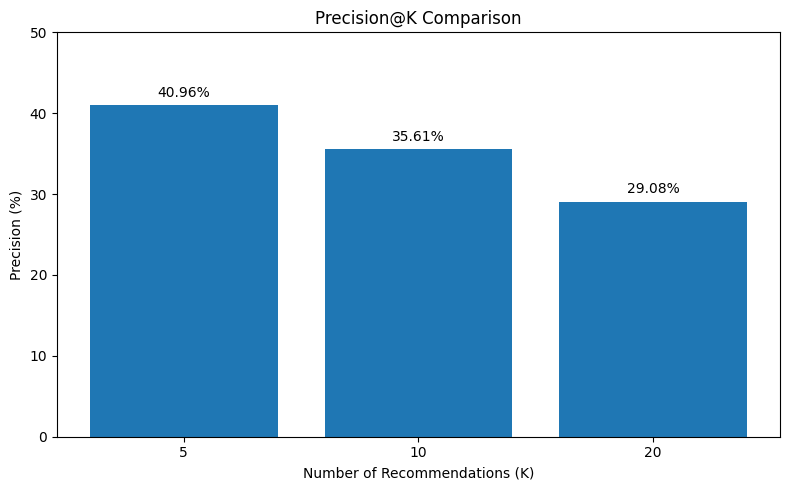

Chart saved successfully!
Saved to: /content/drive/MyDrive/Elevo/Level2/Task5/precision_at_k_comparison.png


In [45]:
import matplotlib.pyplot as plt

# Create Precision@K bar chart
plt.figure(figsize=(8, 5))

plt.bar(
    precision_comparison["K"].astype(str),
    precision_comparison["Precision_Percentage"]
)

plt.title("Precision@K Comparison")
plt.xlabel("Number of Recommendations (K)")
plt.ylabel("Precision (%)")
plt.ylim(0, 50)

# Display values above bars
for i, value in enumerate(
    precision_comparison["Precision_Percentage"]
):
    plt.text(i, value + 1, f"{value:.2f}%", ha="center")

plt.tight_layout()

# Save chart to Google Drive
chart_path = os.path.join(
    project_path,
    "precision_at_k_comparison.png"
)

plt.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved successfully!")
print("Saved to:", chart_path)

In [46]:
# Calculate cosine similarity between movies
item_similarity = cosine_similarity(
    train_user_item_filled.T
)

# Convert to DataFrame
item_similarity_df = pd.DataFrame(
    item_similarity,
    index=train_user_item_filled.columns,
    columns=train_user_item_filled.columns
)

print("Item similarity matrix shape:",
      item_similarity_df.shape)

print("\nFirst five movies' similarity scores:")
display(item_similarity_df.iloc[:5, :5])

Item similarity matrix shape: (1650, 1650)

First five movies' similarity scores:


movie_id,1,2,3,4,5
movie_id,,,,,
1,1.000000,0.357646,0.309390,0.373556,0.233597
2,0.357646,1.000000,0.221600,0.419180,0.282711
3,0.309390,0.221600,1.000000,0.262853,0.144386
4,0.373556,0.419180,0.262853,1.000000,0.273416
5,0.233597,0.282711,0.144386,0.273416,1.000000


In [47]:
# Select a movie
target_movie = 1

# Get similarity scores for the selected movie
similar_movies = item_similarity_df[target_movie]

# Remove the movie itself
similar_movies = similar_movies.drop(target_movie)

# Get the 10 most similar movies
top_10_similar_movies = similar_movies.sort_values(
    ascending=False
).head(10)

# Convert results to DataFrame
similar_movies_df = top_10_similar_movies.reset_index()

similar_movies_df.columns = [
    "movie_id",
    "similarity_score"
]

# Add movie titles
similar_movies_df = similar_movies_df.merge(
    movies,
    on="movie_id",
    how="left"
)

print("10 movies most similar to Movie ID 1:")
display(similar_movies_df)

10 movies most similar to Movie ID 1:


,movie_id,similarity_score,title
0,50,0.639460,Star Wars (1977)
1,181,0.614548,Return of the Jedi (1983)
2,121,0.602836,Independence Day (ID4) (1996)
3,117,0.594402,"Rock, The (1996)"
4,405,0.565266,Mission: Impossible (1996)
5,222,0.559113,Star Trek: First Contact (1996)
6,237,0.557852,Jerry Maguire (1996)
7,151,0.552569,Willy Wonka and the Chocolate Factory (1971)
8,118,0.542992,Twister (1996)
9,7,0.542065,Twelve Monkeys (1995)


In [48]:
# Select target user
target_user = 1

# Get movies rated by User 1 in the training dataset
user_movie_ratings = train_ratings[
    train_ratings["user_id"] == target_user
].set_index("movie_id")["rating"]

# Get movie similarities for movies rated by User 1
similarity_to_rated = item_similarity_df[
    user_movie_ratings.index
]

# Calculate weighted predicted ratings
weighted_sum = similarity_to_rated.dot(user_movie_ratings)

similarity_sum = similarity_to_rated.sum(axis=1)

predicted_ratings = weighted_sum / similarity_sum

# Exclude movies already rated by User 1
predicted_ratings = predicted_ratings.drop(
    user_movie_ratings.index,
    errors="ignore"
)

# Rank recommendations
item_recommendations = predicted_ratings.sort_values(
    ascending=False
)

# Display top 10 recommendations
item_recommendations_df = item_recommendations.head(10).reset_index()

item_recommendations_df.columns = [
    "movie_id",
    "predicted_rating"
]

# Add movie titles
item_recommendations_df = item_recommendations_df.merge(
    movies,
    on="movie_id",
    how="left"
)

print("Top 10 item-based recommendations for User 1:")
display(item_recommendations_df)

Top 10 item-based recommendations for User 1:


,movie_id,predicted_rating,title
0,1342,5.000000,"Convent, The (Convento, O) (1995)"
1,1414,4.736240,Coldblooded (1995)
2,1259,4.504732,Pie in the Sky (1995)
3,1347,4.408069,"Ballad of Narayama, The (Narayama Bushiko) (1958)"
4,1654,4.354119,Chairman of the Board (1998)
5,1618,4.335656,King of New York (1990)
6,1354,4.333797,Venice/Venice (1992)
7,1500,4.333098,Santa with Muscles (1996)
8,1332,4.306183,My Life and Times With Antonin Artaud (En comp...
9,1323,4.274474,"Wooden Man's Bride, The (Wu Kui) (1994)"


In [49]:
# Count ratings received by each movie in training data
movie_rating_counts = train_ratings.groupby(
    "movie_id"
)["rating"].count()

# Keep movies with at least 20 ratings
popular_movies = movie_rating_counts[
    movie_rating_counts >= 20
].index

# Filter predictions to include popular movies only
filtered_item_recommendations = item_recommendations[
    item_recommendations.index.isin(popular_movies)
]

# Select top 10 recommendations
filtered_item_recommendations_df = (
    filtered_item_recommendations.head(10).reset_index()
)

filtered_item_recommendations_df.columns = [
    "movie_id",
    "predicted_rating"
]

# Add movie titles and rating counts
filtered_item_recommendations_df = (
    filtered_item_recommendations_df
    .merge(movies, on="movie_id", how="left")
    .merge(
        movie_rating_counts.rename("total_ratings"),
        on="movie_id",
        how="left"
    )
)

print("Improved item-based recommendations for User 1:")
display(filtered_item_recommendations_df)

Improved item-based recommendations for User 1:


,movie_id,predicted_rating,title,total_ratings
0,863,4.135614,"Garden of Finzi-Contini, The (Giardino dei Fin...",22
1,971,4.101343,Mediterraneo (1991),28
2,813,4.079365,"Celluloid Closet, The (1995)",43
3,1176,4.070428,Welcome To Sarajevo (1997),20
4,1005,4.050056,"Double vie de Véronique, La (Double Life of Ve...",20
5,6,4.047083,Shanghai Triad (Yao a yao yao dao waipo qiao) ...,20
6,1021,4.046267,8 1/2 (1963),29
7,512,4.042816,Wings of Desire (1987),47
8,753,4.042379,Burnt By the Sun (1994),20
9,60,4.041993,Three Colors: Blue (1993),60


In [50]:
# Evaluation settings
K = 10
MIN_RATINGS = 20

item_precision_scores = []

# Evaluate each user
for user_id in train_user_item_filled.index:

    # Get movies rated by the target user
    user_ratings = train_ratings[
        train_ratings["user_id"] == user_id
    ].set_index("movie_id")["rating"]

    # Skip users with no training ratings
    if len(user_ratings) == 0:
        continue

    # Calculate similarity-weighted predictions
    similarity_matrix = item_similarity_df[user_ratings.index]

    weighted_sum = similarity_matrix.dot(user_ratings)
    similarity_sum = similarity_matrix.sum(axis=1)

    predictions = weighted_sum / similarity_sum

    # Exclude movies already rated by the user
    predictions = predictions.drop(
        user_ratings.index,
        errors="ignore"
    )

    # Apply minimum popularity threshold
    predictions = predictions[
        predictions.index.isin(popular_movies)
    ]

    # Select top 10 recommendations
    top_recommendations = set(
        predictions.sort_values(
            ascending=False
        ).head(K).index
    )

    # Get relevant test movies
    relevant_movies = set(
        test_ratings[
            (test_ratings["user_id"] == user_id) &
            (test_ratings["rating"] >= 4)
        ]["movie_id"]
    )

    # Require at least 10 recommendations
    if len(top_recommendations) < K or len(relevant_movies) == 0:
        continue

    # Calculate Precision@10
    relevant_recommendations = (
        top_recommendations.intersection(relevant_movies)
    )

    precision = len(relevant_recommendations) / K

    item_precision_scores.append(precision)

# Calculate average Precision@10
item_precision_at_10 = np.mean(item_precision_scores)

print("Users evaluated:", len(item_precision_scores))
print("Item-based Precision@10:",
      round(item_precision_at_10, 4))
print("Item-based Precision@10 (%):",
      round(item_precision_at_10 * 100, 2), "%")

Users evaluated: 456
Item-based Precision@10: 0.0243
Item-based Precision@10 (%): 2.43 %


In [51]:
# Improved item-based recommendation function

def recommend_item_based(user_id, k=10, n_similar=20):

    # Get ratings from the user's training history
    user_ratings = train_ratings[
        train_ratings["user_id"] == user_id
    ].set_index("movie_id")["rating"]

    rated_movies = set(user_ratings.index)

    predictions = {}

    # Consider movies not rated by the user
    candidate_movies = [
        movie_id for movie_id in item_similarity_df.index
        if movie_id not in rated_movies
        and movie_id in popular_movies
    ]

    for movie_id in candidate_movies:

        # Get similarities between candidate and rated movies
        similarities = item_similarity_df.loc[
            movie_id, user_ratings.index
        ]

        # Select the 20 most similar rated movies
        top_similar = similarities.sort_values(
            ascending=False
        ).head(n_similar)

        # Calculate similarity-weighted prediction
        ratings = user_ratings.loc[top_similar.index]

        if top_similar.sum() > 0:
            predicted_rating = (
                (top_similar * ratings).sum() /
                top_similar.sum()
            )

            predictions[movie_id] = predicted_rating

    # Rank predicted ratings
    recommendations = pd.Series(predictions).sort_values(
        ascending=False
    )

    return recommendations.head(k)


# Generate improved recommendations for User 1
improved_item_recommendations = recommend_item_based(
    user_id=1,
    k=10,
    n_similar=20
)

print("Improved item-based recommendations for User 1:")
display(improved_item_recommendations)

Improved item-based recommendations for User 1:


,0
919,4.628913
936,4.626201
458,4.569337
952,4.567327
222,4.526493
1134,4.524229
228,4.515517
170,4.515171
427,4.514145
277,4.512849


In [52]:
# Evaluation settings
K = 10
improved_item_precision_scores = []

# Evaluate each user
for user_id in train_user_item_filled.index:

    # Generate improved recommendations
    recommendations = recommend_item_based(
        user_id=user_id,
        k=K,
        n_similar=20
    )

    # Get relevant movies from test data
    relevant_movies = set(
        test_ratings[
            (test_ratings["user_id"] == user_id) &
            (test_ratings["rating"] >= 4)
        ]["movie_id"]
    )

    # Skip users without enough recommendations
    if len(recommendations) < K or len(relevant_movies) == 0:
        continue

    # Compare recommendations with relevant test movies
    recommended_movies = set(recommendations.index)

    relevant_recommendations = (
        recommended_movies.intersection(relevant_movies)
    )

    # Calculate Precision@10
    precision = len(relevant_recommendations) / K

    improved_item_precision_scores.append(precision)

# Calculate overall performance
improved_item_precision = np.mean(
    improved_item_precision_scores
)

print("Users evaluated:",
      len(improved_item_precision_scores))

print("Improved item-based Precision@10:",
      round(improved_item_precision, 4))

print("Improved item-based Precision@10 (%):",
      round(improved_item_precision * 100, 2), "%")

Users evaluated: 456
Improved item-based Precision@10: 0.0844
Improved item-based Precision@10 (%): 8.44 %


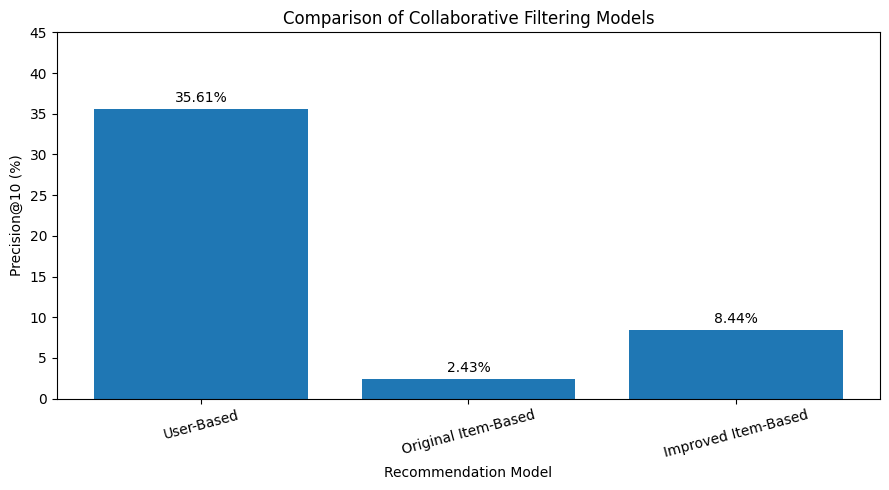

Model comparison chart saved successfully!
Saved to: /content/drive/MyDrive/Elevo/Level2/Task5/collaborative_filtering_comparison.png


In [53]:
# Prepare model comparison
model_comparison = pd.DataFrame({
    "Model": [
        "User-Based",
        "Original Item-Based",
        "Improved Item-Based"
    ],
    "Precision@10": [
        0.3561,
        0.0243,
        0.0844
    ]
})

# Create comparison chart
plt.figure(figsize=(9, 5))

plt.bar(
    model_comparison["Model"],
    model_comparison["Precision@10"] * 100
)

plt.title("Comparison of Collaborative Filtering Models")
plt.xlabel("Recommendation Model")
plt.ylabel("Precision@10 (%)")
plt.ylim(0, 45)
plt.xticks(rotation=15)

# Add values above bars
for i, value in enumerate(
    model_comparison["Precision@10"] * 100
):
    plt.text(i, value + 0.8, f"{value:.2f}%", ha="center")

plt.tight_layout()

# Save chart
comparison_path = os.path.join(
    project_path,
    "collaborative_filtering_comparison.png"
)

plt.savefig(comparison_path, dpi=300, bbox_inches="tight")
plt.show()

print("Model comparison chart saved successfully!")
print("Saved to:", comparison_path)

In [54]:
from sklearn.decomposition import TruncatedSVD

# Initialise the SVD model
svd_model = TruncatedSVD(
    n_components=50,
    random_state=42
)

print("SVD model initialised successfully!")
print("Number of latent factors:", svd_model.n_components)

SVD model initialised successfully!
Number of latent factors: 50


In [55]:
# Fit SVD model on the training user-item matrix
svd_user_factors = svd_model.fit_transform(
    train_user_item_filled
)

print("SVD model trained successfully!")

print("User latent factors shape:",
      svd_user_factors.shape)

print("Movie latent factors shape:",
      svd_model.components_.shape)

SVD model trained successfully!
User latent factors shape: (943, 50)
Movie latent factors shape: (50, 1650)


In [56]:
# Reconstruct predicted ratings
svd_predicted_ratings = np.dot(
    svd_user_factors,
    svd_model.components_
)

# Convert predictions into a DataFrame
svd_predictions_df = pd.DataFrame(
    svd_predicted_ratings,
    index=train_user_item_filled.index,
    columns=train_user_item_filled.columns
)

print("Predicted ratings matrix shape:",
      svd_predictions_df.shape)

print("\nPredicted ratings for the first five users and movies:")
display(svd_predictions_df.iloc[:5, :5])

Predicted ratings matrix shape: (943, 1650)

Predicted ratings for the first five users and movies:


movie_id,1,2,3,4,5
user_id,,,,,
1,4.704285,1.298870,1.010967,0.994587,0.965622
2,2.510120,0.047665,-0.270701,0.027412,-0.160782
3,-0.077520,0.089754,0.008483,-0.046775,0.123106
4,0.049867,-0.117662,0.055946,0.021437,-0.122553
5,2.215570,0.609298,0.283439,0.697591,-0.275975


In [57]:
# Select target user
target_user = 1

# Get predicted ratings for User 1
user_predictions = svd_predictions_df.loc[target_user]

# Identify movies already rated by User 1
rated_movies = set(
    train_ratings[
        train_ratings["user_id"] == target_user
    ]["movie_id"]
)

# Exclude movies already rated
unseen_predictions = user_predictions[
    ~user_predictions.index.isin(rated_movies)
]

# Select the top 10 recommended movies
top_svd_recommendations = unseen_predictions.sort_values(
    ascending=False
).head(10)

# Convert recommendations to DataFrame
svd_recommendations_df = top_svd_recommendations.reset_index()

svd_recommendations_df.columns = [
    "movie_id",
    "predicted_rating"
]

# Add movie titles
svd_recommendations_df = svd_recommendations_df.merge(
    movies,
    on="movie_id",
    how="left"
)

print("Top 10 SVD recommendations for User 1:")
display(svd_recommendations_df)

Top 10 SVD recommendations for User 1:


,movie_id,predicted_rating,title
0,174,3.214156,Raiders of the Lost Ark (1981)
1,98,3.141665,"Silence of the Lambs, The (1991)"
2,183,3.032147,Alien (1979)
3,285,2.859810,Secrets & Lies (1996)
4,180,2.474426,Apocalypse Now (1979)
5,12,2.434879,"Usual Suspects, The (1995)"
6,70,2.165647,Four Weddings and a Funeral (1994)
7,732,2.118481,Dave (1993)
8,188,2.049959,Full Metal Jacket (1987)
9,200,2.042700,"Shining, The (1980)"


In [58]:
# Evaluation settings
K = 10
svd_precision_scores = []

# Evaluate each user
for user_id in train_user_item_filled.index:

    # Get predicted ratings for the user
    user_predictions = svd_predictions_df.loc[user_id]

    # Identify movies already rated in training data
    rated_movies = set(
        train_ratings[
            train_ratings["user_id"] == user_id
        ]["movie_id"]
    )

    # Exclude movies already rated
    unseen_predictions = user_predictions[
        ~user_predictions.index.isin(rated_movies)
    ]

    # Select top 10 recommendations
    top_recommendations = set(
        unseen_predictions.sort_values(
            ascending=False
        ).head(K).index
    )

    # Get relevant movies from test data
    relevant_movies = set(
        test_ratings[
            (test_ratings["user_id"] == user_id) &
            (test_ratings["rating"] >= 4)
        ]["movie_id"]
    )

    # Skip users without enough recommendations
    if len(top_recommendations) < K or len(relevant_movies) == 0:
        continue

    # Calculate Precision@10
    relevant_recommendations = (
        top_recommendations.intersection(relevant_movies)
    )

    precision = len(relevant_recommendations) / K

    svd_precision_scores.append(precision)

# Calculate average Precision@10
svd_precision_at_10 = np.mean(svd_precision_scores)

print("Users evaluated:", len(svd_precision_scores))

print("SVD Precision@10:",
      round(svd_precision_at_10, 4))

print("SVD Precision@10 (%):",
      round(svd_precision_at_10 * 100, 2), "%")

Users evaluated: 456
SVD Precision@10: 0.33
SVD Precision@10 (%): 33.0 %


In [59]:
# Create final model comparison table
final_comparison = pd.DataFrame({
    "Model": [
        "User-Based Collaborative Filtering",
        "Original Item-Based Collaborative Filtering",
        "Improved Item-Based Collaborative Filtering",
        "SVD Matrix Factorization"
    ],
    "Precision@10": [
        0.3561,
        0.0243,
        0.0844,
        0.3300
    ]
})

# Convert scores to percentages
final_comparison["Precision_Percentage"] = (
    final_comparison["Precision@10"] * 100
)

# Sort models by performance
final_comparison = final_comparison.sort_values(
    by="Precision@10",
    ascending=False
).reset_index(drop=True)

print("FINAL RECOMMENDATION MODEL COMPARISON")
display(final_comparison)

# Save results to Google Drive
results_path = os.path.join(
    project_path,
    "final_model_comparison.csv"
)

final_comparison.to_csv(results_path, index=False)

print("\nFinal comparison saved successfully!")
print("Saved to:", results_path)

FINAL RECOMMENDATION MODEL COMPARISON


,Model,Precision@10,Precision_Percentage
0,User-Based Collaborative Filtering,0.3561,35.61
1,SVD Matrix Factorization,0.3300,33.00
2,Improved Item-Based Collaborative Filtering,0.0844,8.44
3,Original Item-Based Collaborative Filtering,0.0243,2.43



Final comparison saved successfully!
Saved to: /content/drive/MyDrive/Elevo/Level2/Task5/final_model_comparison.csv


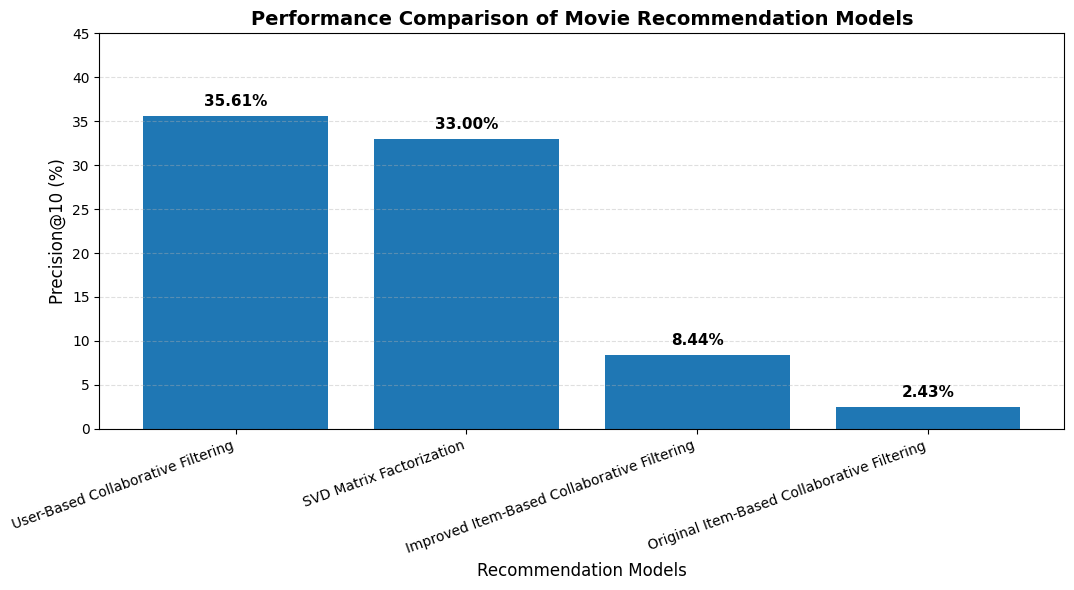

Final comparison graph saved successfully!
Saved to: /content/drive/MyDrive/Elevo/Level2/Task5/final_recommendation_model_comparison.png


In [60]:
# Final recommendation model comparison graph

plt.figure(figsize=(11, 6))

bars = plt.bar(
    final_comparison["Model"],
    final_comparison["Precision_Percentage"]
)

plt.title(
    "Performance Comparison of Movie Recommendation Models",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Recommendation Models", fontsize=12)
plt.ylabel("Precision@10 (%)", fontsize=12)

plt.ylim(0, 45)
plt.xticks(rotation=20, ha="right")

# Add percentage labels above each bar
for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.8,
        f"{height:.2f}%",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()

# Save final graph
final_chart_path = os.path.join(
    project_path,
    "final_recommendation_model_comparison.png"
)

plt.savefig(
    final_chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Final comparison graph saved successfully!")
print("Saved to:", final_chart_path)